In [12]:
#!/usr/bin/env python3

import os, sys
sys.path.append('../')
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
from collections import namedtuple
import sys
sys.path.append('../')

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass
delphesDir = os.path.abspath("../../DelphesLLP")
os.environ['ROOT_INCLUDE_PATH'] = os.path.join(delphesDir,"external")

import ROOT


ROOT.gSystem.Load(os.path.join(delphesDir,"libDelphes.so"))

ROOT.gInterpreter.Declare('#include "classes/SortableObject.h"')
ROOT.gInterpreter.Declare('#include "classes/DelphesClasses.h"')
ROOT.gInterpreter.Declare('#include "external/ExRootAnalysis/ExRootTreeReader.h"')



True

## Read events

In [13]:
files = {
         r'$\Delta m = 15$ GeV' : '../../processFolders/pp2chi1chi2_01j_nosmear_13TeV/Events/run_53/chi1chi2_01j_mS_500_m2_205_m1_195_dm_15_ctau_20.0_delphes_card_b2tf_nosmear.root',
         r'$\Delta m = 100$ GeV' : '../../processFolders/pp2chi1chi2_01j_nosmear_13TeV/Events/run_59/chi1chi2_01j_mS_500_m2_205_m1_195_dm_100_ctau_20.0_delphes_card_b2tf_nosmear.root'
        }

c_light = 2.99792458e8

### Get LLP decay position and time from truth level events (does not include propagation)

In [17]:
rDecaysDict = {}
metDict = {}
decayVertex = namedtuple('decayVertex',['x','y','z','t','beta','l','rho'])
for label,file in files.items():
    if not os.path.isfile(file):
        print(f"File {file} not found, skipping")
        continue
    f = ROOT.TFile(file,'read')
    tree = f.Get("Delphes")
    nevts = tree.GetEntries()
    rDecays = []
    metList = []
    for ievt in range(nevts):
        tree.GetEntry(ievt)

        llpDec = {}
        llpBoost = {}
        llps = list(tree.llpParticles)
        for illp,llp in enumerate(llps):
            p = np.array([llp.Px,llp.Py,llp.Pz,llp.E])
            beta = np.linalg.norm(p[:3])/p[3]
            llpBoost[illp] = beta
        
        for d in tree.llpDirectDaughters:
            illp = d.M1
            if illp in llpDec:
                continue
            beta = llpBoost[illp]
            decayVtx = decayVertex(d.X*1e-3,d.Y*1e-3,d.Z*1e-3,d.T,beta,
                                   float(np.linalg.norm([d.X,d.Y,d.Z])*1e-3),
                                   float(np.linalg.norm([d.X,d.Y])*1e-3))
            t_readout = decayVtx.t-decayVtx.l/c_light
            t_readout = t_readout*1e9
            llpDec[illp] = decayVtx._replace(t=t_readout)
        decs = sorted(llpDec.values(), key = lambda d : d[3])
        if len(decs) != 1:
            raise ValueError(f"Event {ievt} has {len(decs)} decays, expected 1")
        rDecays.append(decs[0])
        metList.append(tree.L1METOnTime.At(0).MET)
    f.Close()
    rDecaysDict[label] = np.array(rDecays,dtype=[(field,'f8') for field in decayVertex._fields])
    metDict[label] = np.array(metList,dtype='f8')

In [4]:
for label,rDecays in rDecaysDict.items():
    print(f"{label}: {len(rDecays)} events")
    print(rDecays.shape)

$\Delta m = 15$ GeV: 26191 events
(26191,)
$\Delta m = 100$ GeV: 25932 events
(25932,)


# Plot decay time

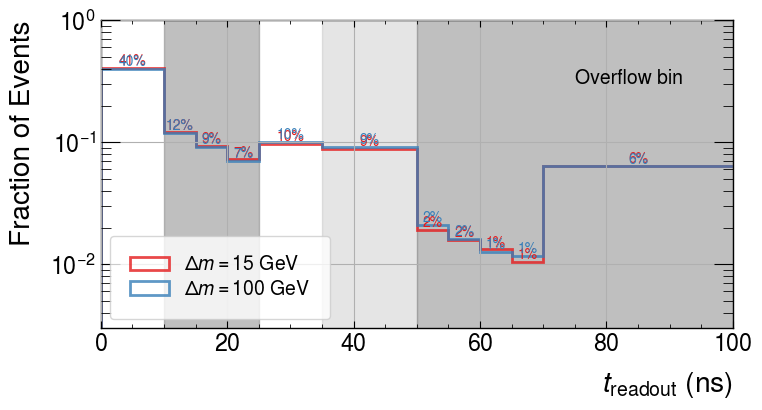

In [5]:
fig = plt.figure(figsize=(8,4))
bins = [0.,10.,15.,20.,25.,35.,50.,55.,60.,65.,70.,10000.]
cmap = mpl.colormaps['Set1']
colors = cmap(list(range(len(rDecaysDict))))
for icurve,label in enumerate(rDecaysDict.keys()):
    rDecay = rDecaysDict[label]
    h,_,patches = plt.hist(rDecay['t'],bins=bins,
             histtype='step',
             weights=[1.0/len(rDecay)]*len(rDecay),
             label=label,linewidth=2,color=colors[icurve],alpha=0.8)
    for i in range(len(bins)-1):
        if h[i] == 0:
            continue
        xpos = 0.5*(bins[i]+min(bins[i+1],100.))
        plt.text(xpos,h[i]*(1.0+0.0*icurve),f"{100*h[i]:.0f}%",ha='center',va='bottom',
                 fontsize=10,color=colors[icurve])
plt.yscale('log')
plt.xlabel(r'$t_{\rm readout}$ (ns)')
plt.ylabel('Fraction of Events')
# plt.vlines(x=[10.,25.,35.],ymin=1e-5,ymax=1,linestyles='dashed',colors='red')
plt.text(75.,0.3,"Overflow bin")
plt.fill_betweenx(y=[1e-5,1],x1=10,x2=25,color='gray',alpha=0.5)
plt.fill_betweenx(y=[1e-5,1],x1=35,x2=50,color='gray',alpha=0.2)
plt.fill_betweenx(y=[1e-5,1],x1=50,x2=100,color='gray',alpha=0.5)
plt.xlim(0.,100)
plt.ylim(3e-3,1)
plt.legend(loc='lower left',framealpha=0.8,frameon=True)
plt.grid()
plt.show()

# Plot decay length

<Figure size 600x400 with 0 Axes>

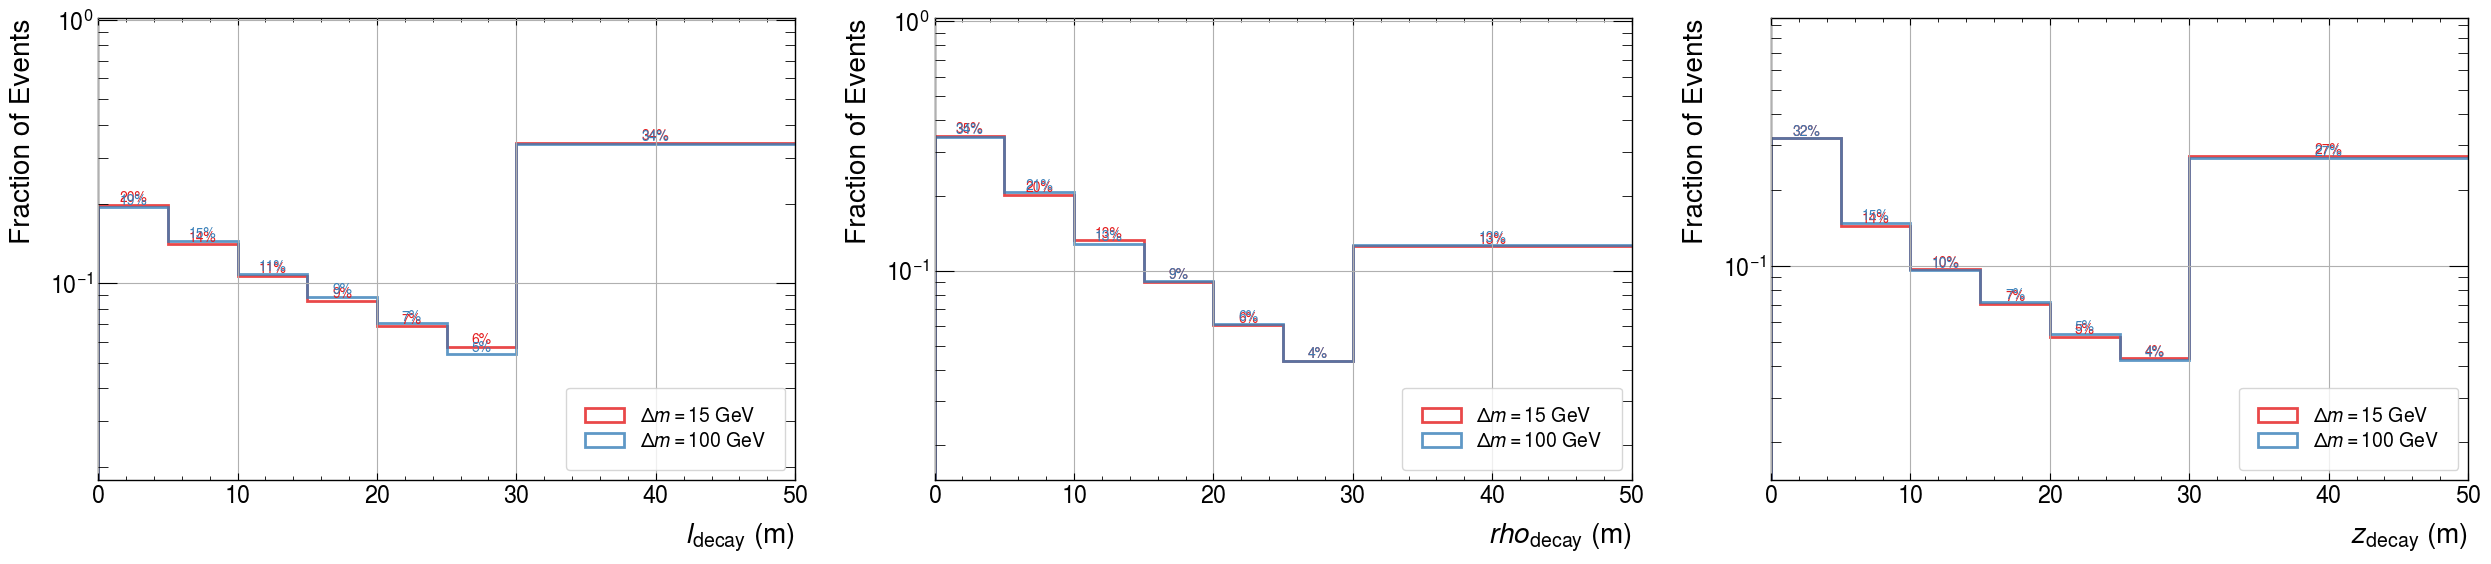

In [6]:
fig = plt.figure(figsize=(6,4))
bins = [0.,5.,10.,15.,20.,25.,30.,1000.]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(10*3, 6*1))

for i,var in enumerate(['l','rho','z']):
    for icurve,label in enumerate(rDecaysDict.keys()):
        rDecay = rDecaysDict[label]
        h,_,patches = axes[i].hist(np.abs(rDecay[var]),bins=bins,
                histtype='step',
                weights=[1.0/len(rDecay)]*len(rDecay),
                label=label,linewidth=2,color=colors[icurve],alpha=0.8)
        for ib in range(len(bins)-1):
            if h[ib] < 0.01:
                continue
            xpos = 0.5*(bins[ib]+min(bins[ib+1],50.))
            axes[i].text(xpos,h[ib]*(1.0+0.0*icurve),f"{100*h[ib]:.0f}%",ha='center',va='bottom',
                    fontsize=10,color=colors[icurve])
    axes[i].set_yscale('log')
    axes[i].set_xlabel(r'$%s_{\rm decay}$ (m)' %var)
    axes[i].set_ylabel('Fraction of Events')
    axes[i].set_xlim(0.,50)
    axes[i].set_ylim(min(h)/3.,max(h)*3.0)
    axes[i].legend(loc='lower right',framealpha=0.8,frameon=True)
    axes[i].grid()
plt.show()

## Define auxiliary functions

In [7]:
@np.vectorize
def in_hcal(z,rho):

    if 4.3 < abs(z) < 5.0 and rho < 3.5:
        return True
    elif 2.0 < rho < 3.5 and abs(z) < 4.3:
        return True
    else:
        return False
@np.vectorize
def in_ms(z,rho):

    if 7.0 < abs(z) < 13.0 and rho < 7.5:
        return True
    elif 3.5 < rho < 7.5 and abs(z) < 7.0:
        return True
    else:
        return False

@np.vectorize
def in_N(t):
    
    if t < 10.0:
        return True
    else:
        return False

@np.vectorize
def in_Np1(t):

    if 25.0 < t < 50.0:
        return True
    else:
        return False

### Split LLPs decaying in N-1 and N

In [8]:
ptsDict_ontime = {}
ptsDict_delayed = {}
for label,rDecay in rDecaysDict.items():
    ptsDict_ontime[label] = rDecay[in_N(rDecay['t'])]
    ptsDict_delayed[label] = rDecay[in_Np1(rDecay['t'])]
    print(f'{label} : decays in N-1 = {len(ptsDict_ontime[label])/len(rDecay):1.4f}, decays in N = {len(ptsDict_delayed[label])/len(rDecay):1.4f}')

$\Delta m = 15$ GeV : decays in N-1 = 0.4067, decays in N = 0.1843
$\Delta m = 100$ GeV : decays in N-1 = 0.4016, decays in N = 0.1917


# Plot decay position

### Plot decays

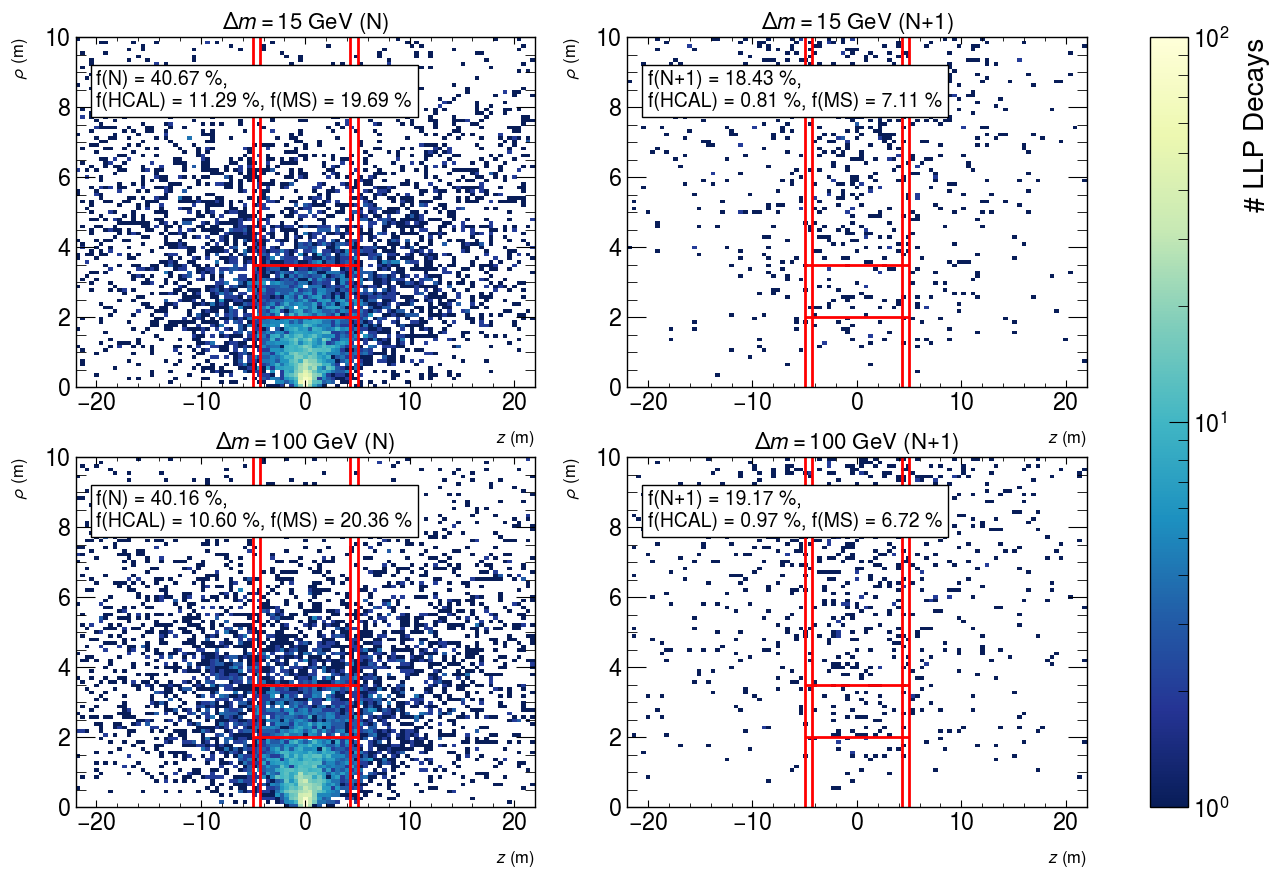

In [9]:


fig, axes = plt.subplots(nrows=len(rDecaysDict), ncols=2, figsize=(8*2, 5*len(rDecaysDict)))

images = []
for j,label in enumerate(rDecaysDict.keys()):
    for i,pts in enumerate([ptsDict_ontime[label],ptsDict_delayed[label]]):
        ax = axes[j,i]
        _,_,_,im = ax.hist2d(pts['z'],pts['rho'],
            bins=[np.linspace(-22,22,100),np.linspace(0.,10.,100)],
            cmap = mpl.colormaps['YlGnBu_r'], 
            norm = mpl.colors.LogNorm(vmin=1.0,vmax=100.))
        if i == 0:
            ax.set_title(f'{label} (N)',fontsize=16)
        else:
            ax.set_title(f'{label} (N+1)',fontsize=16)
        images.append(im)

        nHcal = sum([in_hcal(z=pt['z'],rho=pt['rho']) for pt in pts])
        nHcal = (100.0*nHcal)/len(pts)

        nMS = sum([in_ms(z=pt['z'],rho=pt['rho']) for pt in pts])
        nMS = (100.0*nMS)/len(pts)

        n = 100.0*len(pts)/len(rDecaysDict[label])
        if i == 0:
            ax.text(-20.,8.,f'f(N) = {n:1.2f} %,\nf(HCAL) = {nHcal:1.2f} %, f(MS) = {nMS:1.2f} %',alpha=1.0,fontsize=14, bbox=dict(facecolor='white', alpha=1.0))
        else:
            ax.text(-20.,8.,f'f(N+1) = {n:1.2f} %,\nf(HCAL) = {nHcal:1.2f} %, f(MS) = {nMS:1.2f} %',alpha=1.0,fontsize=14, bbox=dict(facecolor='white', alpha=1.0))

        ax.vlines(x=[4.3,5.0],ymin=0.,ymax=10.,colors='red')
        ax.vlines(x=[-4.3,-5.0],ymin=0.,ymax=10.,colors='red')
        ax.hlines(y=[2.0,3.5],xmin=-5.0,xmax=5.0,colors='red')
        ax.set_xlabel(r'$z$ (m)',fontsize=12)
        ax.set_ylabel(r'$\rho$ (m)',fontsize=12)

fig.colorbar(images[0], ax=axes.ravel().tolist(), orientation='vertical', label='# LLP Decays')        
plt.show()

### Plot Boost

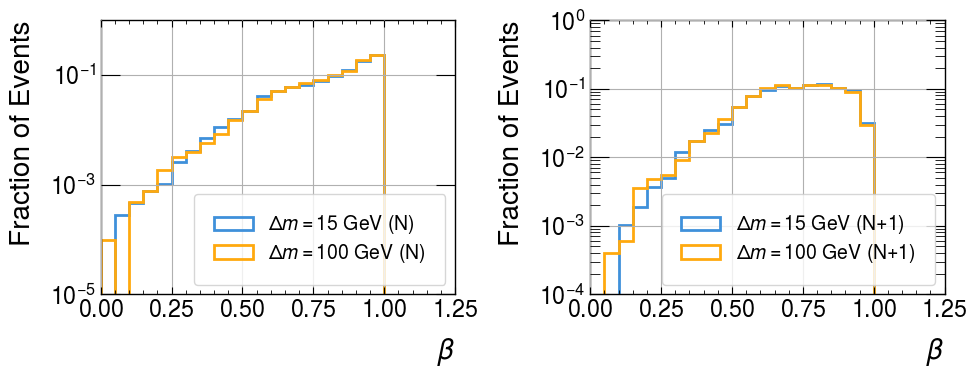

In [10]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,pts in ptsDict_ontime.items():
    axes[0].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N)',linewidth=2)
    pts = ptsDict_delayed[label]
    axes[1].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N+1)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='lower right',framealpha=0.8,frameon=True)
    ax.grid()
plt.tight_layout()
plt.show()

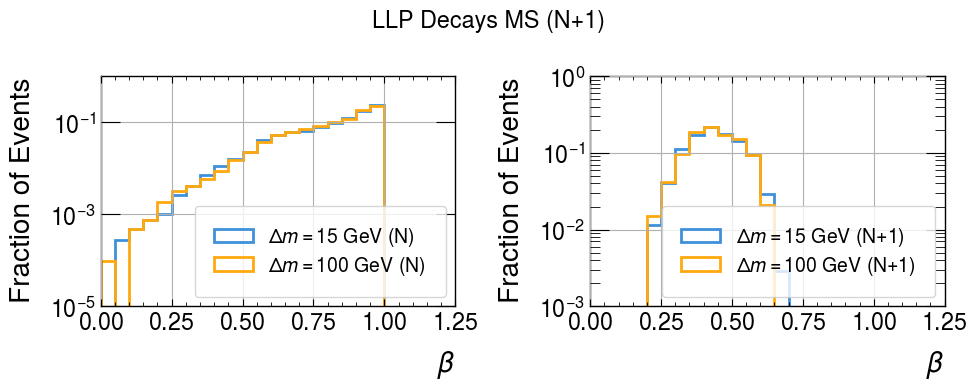

In [11]:

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(5*2, 4))


for label,pts in ptsDict_ontime.items():    
    axes[0].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N)',linewidth=2)
    pts = ptsDict_delayed[label]
    pts = pts[in_ms(pts['z'],pts['rho'])]
    axes[1].hist(pts['beta'],bins=np.linspace(0.,1.2,25),
             histtype='step',
             weights=[1.0/len(pts)]*len(pts),
             label=f'{label} (N+1)',linewidth=2)
for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel(r'$\beta$')
    ax.set_ylabel('Fraction of Events')
    ax.legend(loc='lower right',framealpha=0.8,frameon=True)
    ax.grid()
plt.suptitle('LLP Decays MS (N+1)')
plt.tight_layout()
plt.show()

# Plot Missing Energy (N)

$\Delta m = 15$ GeV 0.12679928219617426
$\Delta m = 100$ GeV 0.10060928582446398


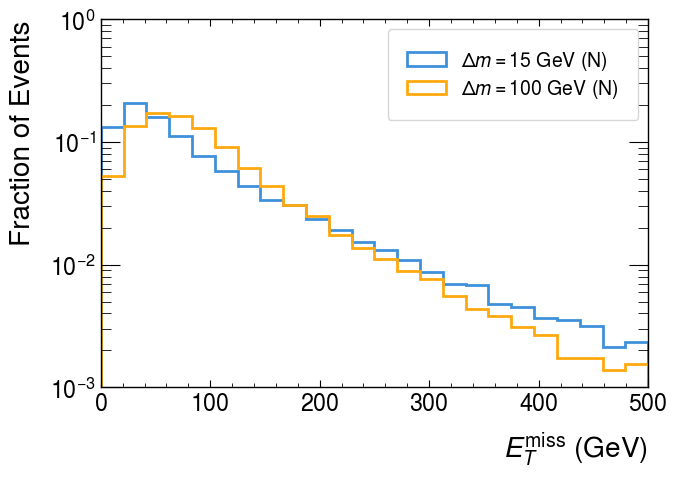

In [23]:

fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(7, 5))

for label,metList in metDict.items():
    axes.hist(metList,bins=np.linspace(0.,500.0,25),
             histtype='step',
             weights=[1.0/len(metList)]*len(metList),
             label=f'{label} (N)',linewidth=2)
    axes.set_yscale('log')
    axes.set_xlabel(r'$E_T^{\rm miss}$ (GeV)')
    axes.set_ylabel('Fraction of Events')
    axes.legend(loc='upper right',framealpha=0.8,frameon=True)
    axes.grid()
    print(label,len(metList[metList > 200.0])/len(metList))
plt.tight_layout()
plt.show()